In [ ]:
import numpy as np
import math
import matplotlib.pyplot as plt

# Problem data
gamma = 1.4
L = 1.0
x_start, x_end = -L, -0.25
M_inlet = 0.5902487609884511

def A_of_x(x: np.ndarray) -> np.ndarray:
    # A* cancels in ln(A_{i+1}/A_i), so set A* = 1
    return 1.0 + 0.2*(x/L)**2

def march_M(x0: float, x1: float, dx: float, M0: float, gamma: float):
    n = int(round((x1 - x0)/dx))
    x = np.linspace(x0, x1, n+1)
    A = A_of_x(x)
    M = np.empty_like(x)
    M2 = M0**2
    M[0] = M0

    for i in range(n):
        eps_A = math.log(A[i+1]/A[i])
        # epsilon_{M^2} = -[(2 + (gamma-1) M^2)/(1 - M^2)] * epsilon_A
        eps_M2 = - (2.0 + (gamma - 1.0)*M2) / (1.0 - M2) * eps_A
        M2 = M2 * math.exp(eps_M2)
        M[i+1] = math.sqrt(M2)
    return x, M

def max_rel_diff_coarse_vs_fine(dx: float):
    x_c, M_c = march_M(x_start, x_end, dx, M_inlet, gamma)
    x_f, M_f = march_M(x_start, x_end, dx/2, M_inlet, gamma)
    # Fine grid should contain coarse nodes exactly for these dx choices
    M_f_on_c = M_f[::2]
    rel = np.abs(M_c - M_f_on_c) / np.abs(M_f_on_c)
    return rel.max(), x_c, M_c

# Convergence study: choose dx so that changing dx -> dx/2 changes M_num by <= 0.1% on [-1, -0.25]
dx = 0.05
history = []
for _ in range(10):
    err, _, _ = max_rel_diff_coarse_vs_fine(dx)
    history.append((dx, err))
    if err <= 1e-3:
        break
    dx /= 2.0

dx_selected, err_selected = history[-1]
x_num, M_num = march_M(x_start, x_end, dx_selected, M_inlet, gamma)

dx_selected, err_selected, history[:6]

(0.003125,
 np.float64(0.0008806286191537701),
 [(0.05, np.float64(0.010246500398461431)),
  (0.025, np.float64(0.0059708296060210385)),
  (0.0125, np.float64(0.0032662322769180306)),
  (0.00625, np.float64(0.0017159231891522846)),
  (0.003125, np.float64(0.0008806286191537701))])

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/M_num_local_epsilon_marching.png'

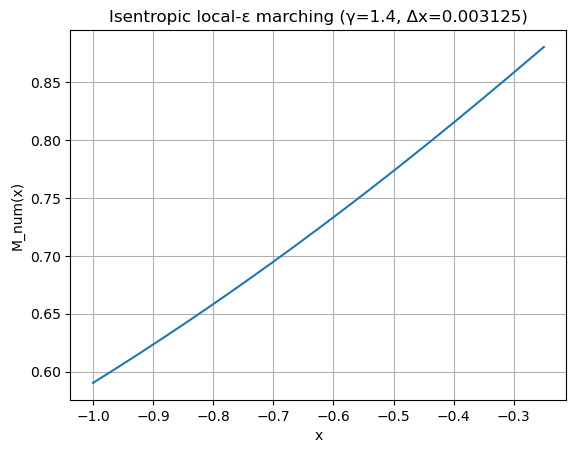

In [2]:
# Plot M_num(x) for the selected dx
plt.figure()
plt.plot(x_num, M_num)
plt.xlabel("x")
plt.ylabel("M_num(x)")
plt.title(f"Isentropic local-ε marching (γ={gamma}, Δx={dx_selected:g})")
plt.grid(True)
plot_path = "M_num_local_epsilon_marching.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

plot_path

In [3]:
import numpy as np
import math
import matplotlib.pyplot as plt

gamma = 1.4
L = 1.0

def area_ratio_from_M(M: float, gamma: float) -> float:
    term = (2.0/(gamma + 1.0)) * (1.0 + 0.5*(gamma - 1.0)*M*M)
    expo = (gamma + 1.0) / (2.0*(gamma - 1.0))
    return (1.0/M) * (term**expo)

def M_exact_subsonic_from_R(R: float, gamma: float, tol: float = 1e-12, max_it: int = 200) -> float:
    # Solve area_ratio_from_M(M) = R for the subsonic root M in (0,1).
    # We avoid the endpoints to keep evaluation finite and to stay off M=1.
    a = 1e-12
    b = 1.0 - 1e-12
    fa = area_ratio_from_M(a, gamma) - R
    fb = area_ratio_from_M(b, gamma) - R
    if fa * fb > 0.0:
        raise ValueError(f"Failed to bracket subsonic root for R={R:g}: fa={fa:g}, fb={fb:g}")
    for _ in range(max_it):
        c = 0.5*(a + b)
        fc = area_ratio_from_M(c, gamma) - R
        if abs(fc) <= tol:
            return c
        if fa * fc <= 0.0:
            b = c
            fb = fc
        else:
            a = c
            fa = fc
    return 0.5*(a + b)

def R_of_x(x: np.ndarray) -> np.ndarray:
    return 1.0 + 0.2*(x/L)**2

# Use the same x-grid as your numerical march (x_num, M_num) from 2.c.ii
R = R_of_x(x_num)
M_exact = np.array([M_exact_subsonic_from_R(Ri, gamma) for Ri in R])

rel_err = np.abs(M_num - M_exact) / np.abs(M_exact)

plt.figure()
plt.plot(x_num, rel_err)
plt.xlabel("x")
plt.ylabel(r"$|M_{\mathrm{num}}-M_{\mathrm{exact}}|/|M_{\mathrm{exact}}|$")
plt.title("Relative error on subsonic branch (x in [-L, -0.25])")
plt.grid(True)
plt.show()

ValueError: 
|M_{\\mathrm{num}}-M_{\\mathrm{exact}}|/|M_{\\mathrm{exact}}|
    ^
ParseSyntaxException: Expected end_group, found '\'  (at char 4), (line:1, col:5)

<Figure size 640x480 with 1 Axes>